# Jupyter Notebook for Principle Component Analysis


In this section we:

- Select a numeric feature set
- Filter out low-minute players
- Standardize features
- Fit PCA and inspect explained variance
- Visualize:
  - Scree plot (variance per component)
  - Cumulative explained variance
  - 2D projection on first two principal components

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import numpy as np


In [5]:
PATH = "../../statsbomb_pipeline/data/processed/player_season_model_dataset.csv"

df = pd.read_csv(PATH)
# Core numeric features for PCA
pca_features = [
    "minutes_played_total",
    "matches_played",
    "xThreat_total",
    "xThreat_pass_total",
    "xThreat_carry_total",
    "xg_total",
    "xThreat_per90",
    "xThreat_pass_per90",
    "xThreat_carry_per90",
]

# Optional: filter out tiny-minute players (keeps things less noisy)
MIN_MINUTES = 900  # tweak if needed
pca_df = df[df["minutes_played_total"] >= MIN_MINUTES].copy()

print("PCA sample size:", pca_df.shape[0])
pca_df[pca_features].describe()



PCA sample size: 324


,minutes_played_total,matches_played,xThreat_total,xThreat_pass_total,xThreat_carry_total,xg_total,xThreat_per90,xThreat_pass_per90,xThreat_carry_per90
count,324.000000,324.000000,324.000000,324.000000,324.000000,324.000000,324.000000,324.000000,324.000000
mean,2098.251389,27.179012,2.462925,2.080449,0.382476,2.691860,0.102563,0.085877,0.016686
std,732.160969,7.191244,1.813325,1.650705,0.528014,3.404107,0.064838,0.058826,0.024556
min,900.000000,10.000000,-0.554043,-0.691771,-1.307814,0.000000,-0.053304,-0.063513,-0.057734
25%,1460.279167,22.000000,1.229515,1.059426,0.056367,0.642783,0.059545,0.050844,0.002425
50%,2044.175000,28.000000,2.032419,1.730342,0.298787,1.565982,0.092418,0.077066,0.012125
75%,2721.416667,33.000000,3.273249,2.696768,0.584820,3.205529,0.131344,0.109319,0.026512
max,3420.833333,38.000000,10.964723,9.384113,2.690732,22.298685,0.368541,0.311101,0.118233


In [6]:
X = pca_df[pca_features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()  # keep all components
X_pca = pca.fit_transform(X_scaled)

explained_var = pca.explained_variance_ratio_
explained_var


array([4.78949090e-01, 2.06349956e-01, 1.99445907e-01, 8.88906198e-02,
       1.34952801e-02, 7.49831687e-03, 5.37083029e-03, 4.98273927e-17,
       0.00000000e+00])

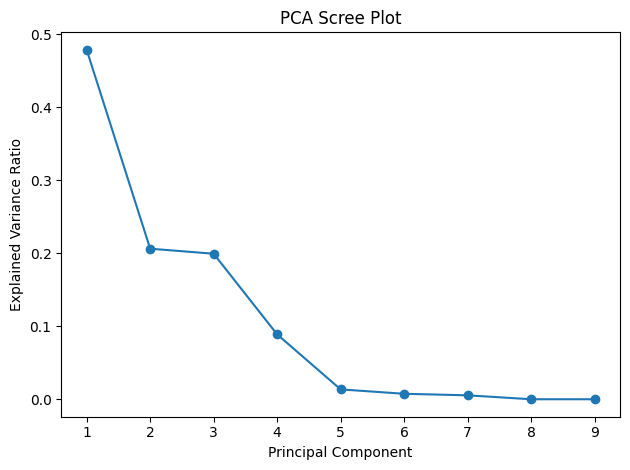

In [8]:
fig, ax = plt.subplots()
components = range(1, len(explained_var) + 1)

ax.plot(components, explained_var, marker="o")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance Ratio")
ax.set_title("PCA Scree Plot")

fig.tight_layout()
plt.show()


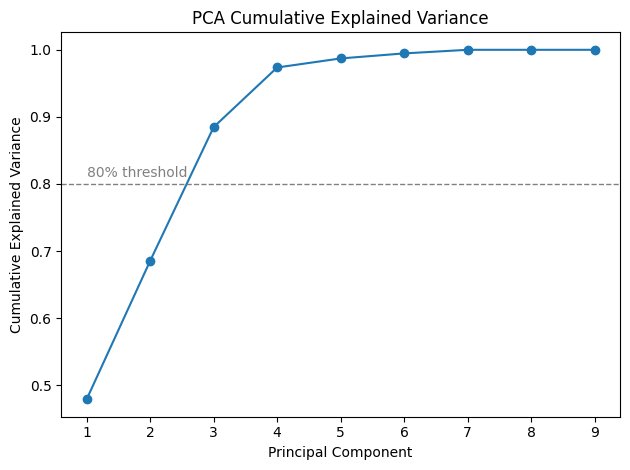

array([0.47894909, 0.68529905, 0.88474495, 0.97363557, 0.98713085,
       0.99462917, 1.        , 1.        , 1.        ])

In [9]:
cum_var = explained_var.cumsum()

fig, ax = plt.subplots()
ax.plot(components, cum_var, marker="o")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("PCA Cumulative Explained Variance")
ax.axhline(0.8, color="grey", linestyle="--", linewidth=1)
ax.text(1, 0.81, "80% threshold", color="grey")

fig.tight_layout()
plt.show()

cum_var


In [10]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i}" for i in range(1, len(pca_features) + 1)],
    index=pca_features,
)

# Inspect the first few components
loadings.iloc[:, :3]


,PC1,PC2,PC3
minutes_played_total,0.279356,-0.153867,0.529633
matches_played,0.278508,-0.064510,0.567012
xThreat_total,0.472929,-0.065848,-0.052528
xThreat_pass_total,0.440640,-0.266668,-0.067932
xThreat_carry_total,0.246599,0.607535,0.031980
xg_total,0.101956,0.189817,0.371780
xThreat_per90,0.417731,0.032565,-0.350233
xThreat_pass_per90,0.385077,-0.238933,-0.345097
xThreat_carry_per90,0.180495,0.658360,-0.098050


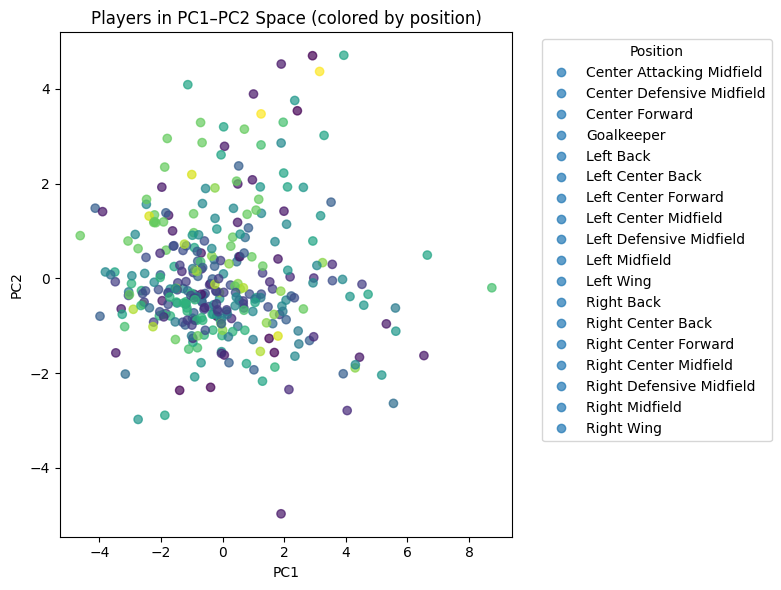

In [15]:
pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pd.factorize(pca_df["position"])[0],
    alpha=0.7,
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Players in PC1–PC2 Space (colored by position)")

# Build a legend manually from unique positions
handles = []
labels = []
for pos, code in zip(*np.unique(pca_df["position"], return_inverse=True)):
    handles.append(plt.Line2D([], [], marker="o", linestyle="", alpha=0.7))
    labels.append(pos)

ax.legend(handles, labels, title="Position", bbox_to_anchor=(1.05, 1), loc="upper left")
fig.tight_layout()
plt.show()


In [16]:
cols_to_show = [
    "player_name",
    "team_name",
    "position",
    "minutes_90s",
    "xThreat_per90",
    "xThreat_total",
    "xg_total",
    "PC1",
]

top_pc1 = (
    pca_df.sort_values("PC1", ascending=False)
          [cols_to_show]
          .head(10)
)

bottom_pc1 = (
    pca_df.sort_values("PC1", ascending=True)
          [cols_to_show]
          .head(10)
)

print("Top 10 players by PC1 (highest scores):")
display(top_pc1)

print("\nBottom 10 players by PC1 (lowest scores):")
display(bottom_pc1)


Top 10 players by PC1 (highest scores):


,player_name,team_name,position,minutes_90s,xThreat_per90,xThreat_total,xg_total,PC1
62,Marc Albrighton,Leicester City,Left Midfield,30.698148,0.357179,10.964723,2.362667,8.737955
24,Kevin De Bruyne,Manchester City,Right Wing,22.272222,0.368541,8.208220,4.502265,6.643323
129,Dimitri Payet,West Ham United,Left Wing,28.590185,0.311640,8.909856,5.067430,6.533674
232,Steven Davis,Southampton,Center Attacking Midfield,28.974815,0.273080,7.912456,2.064006,5.621179
121,Francesc Fàbregas i Soler,Chelsea,Right Defensive Midfield,32.193333,0.246218,7.926591,4.029404,5.608218
207,Danny Drinkwater,Leicester City,Left Center Midfield,33.774074,0.246177,8.314412,1.776188,5.544249
165,Yannick Bolasie Yala,Crystal Palace,Left Wing,23.075556,0.313344,7.230593,4.331838,5.313417
132,Mesut Özil,Arsenal,Center Attacking Midfield,33.824074,0.228892,7.742075,5.966241,5.163322
117,Willian Borges da Silva,Chelsea,Right Wing,30.497407,0.228441,6.966868,3.727556,4.721231
459,Jason Puncheon,Crystal Palace,Center Attacking Midfield,29.130926,0.237588,6.921155,3.575957,4.581359



Bottom 10 players by PC1 (lowest scores):


,player_name,team_name,position,minutes_90s,xThreat_per90,xThreat_total,xg_total,PC1
47,Benik Afobe,AFC Bournemouth,Center Forward,10.394074,-0.053304,-0.554043,1.948933,-4.621936
103,Martin Kelly,Crystal Palace,Right Back,11.599444,-0.024298,-0.281843,0.019187,-4.135782
8,Pablo Javier Zabaleta Girod,Manchester City,Right Back,11.795185,-0.008821,-0.104047,0.094445,-3.980358
487,Duncan Watmore,Sunderland,Left Wing,10.142593,-0.033098,-0.335700,1.994845,-3.896941
382,James Grant Chester,West Bromwich Albion,Left Back,10.706667,-0.001098,-0.011754,0.000000,-3.805764
316,Valon Behrami,Watford,Left Center Midfield,14.488519,-0.012178,-0.176445,0.019907,-3.633879
19,Heung-Min Son,Tottenham Hotspur,Right Wing,12.264444,-0.019236,-0.235916,3.809582,-3.500118
18,Jamaal Lascelles,Newcastle United,Left Center Back,12.792222,0.002966,0.037947,0.838523,-3.485009
502,Arouna Koné,Everton,Left Wing,16.281667,-0.015446,-0.251484,4.593096,-3.466958
2,Memphis Depay,Manchester United,Left Wing,16.459259,-0.017920,-0.294947,4.381855,-3.292645


In [17]:
cols_to_show_pc2 = [
    "player_name",
    "team_name",
    "position",
    "minutes_90s",
    "xThreat_per90",
    "xThreat_pass_per90",
    "xThreat_carry_per90",
    "xg_total",
    "PC2",
]

top_pc2 = (
    pca_df.sort_values("PC2", ascending=False)
          [cols_to_show_pc2]
          .head(10)
)

bottom_pc2 = (
    pca_df.sort_values("PC2", ascending=True)
          [cols_to_show_pc2]
          .head(10)
)

print("Top 10 players by PC2 (highest scores):")
display(top_pc2)

print("\nBottom 10 players by PC2 (lowest scores):")
display(bottom_pc2)


Top 10 players by PC2 (highest scores):


,player_name,team_name,position,minutes_90s,xThreat_per90,xThreat_pass_per90,xThreat_carry_per90,xg_total,PC2
338,Jesús Navas González,Manchester City,Right Wing,25.370000,0.215522,0.109462,0.106060,2.874503,4.708687
136,Wilfried Zaha,Crystal Palace,Right Midfield,27.691111,0.167121,0.070002,0.097119,2.407637,4.699363
344,Jefferson Antonio Montero Vite,Swansea City,Left Wing,15.054815,0.221725,0.103492,0.118233,1.821713,4.523535
414,Jamie Vardy,Leicester City,Left Center Forward,35.217037,0.127005,0.061194,0.065811,22.298685,4.366995
247,Victor Moses,West Ham United,Right Wing,10.882407,0.105773,0.003722,0.102051,1.837627,4.088130
184,Eden Hazard,Chelsea,Left Wing,24.378704,0.119262,0.037801,0.081461,2.394682,3.891293
187,Sadio Mané,Southampton,Center Attacking Midfield,28.932037,0.132491,0.062526,0.069965,12.052078,3.754793
1,Stéphane Sessègnon,West Bromwich Albion,Right Midfield,19.555370,0.212819,0.119653,0.093167,1.250709,3.537010
312,Odion Jude Ighalo,Watford,Left Center Forward,35.025185,0.074952,0.023762,0.051190,16.919278,3.471202
196,Marc Pugh,AFC Bournemouth,Left Midfield,14.857037,0.223998,0.129881,0.094117,2.683968,3.295143



Bottom 10 players by PC2 (lowest scores):


,player_name,team_name,position,minutes_90s,xThreat_per90,xThreat_pass_per90,xThreat_carry_per90,xg_total,PC2
134,Philippe Coutinho Correia,Liverpool,Left Wing,22.652222,0.194782,0.252517,-0.057734,7.128246,-4.966545
306,Bojan Krkíc Pérez,Stoke City,Center Attacking Midfield,18.956111,0.013728,0.065911,-0.052184,4.829387,-2.975303
337,Carles Gil de Pareja Vicent,Aston Villa,Right Wing,15.965741,0.069743,0.114767,-0.045023,1.017690,-2.887668
186,Ben Watson,Watford,Left Defensive Midfield,31.292037,0.212411,0.215267,-0.002856,0.515430,-2.787946
207,Danny Drinkwater,Leicester City,Left Center Midfield,33.774074,0.246177,0.241221,0.004957,1.776188,-2.636389
543,Almen Abdi,Watford,Right Midfield,22.006481,0.054764,0.083593,-0.028829,2.358758,-2.361194
423,Santiago Cazorla González,Arsenal,Left Defensive Midfield,14.472407,0.277273,0.289737,-0.012464,1.784201,-2.344764
348,Fabio Borini,Sunderland,Right Midfield,21.056296,0.104531,0.130080,-0.025548,4.822003,-2.298263
163,Erik Lamela,Tottenham Hotspur,Right Wing,26.424630,0.136125,0.149402,-0.013277,5.872297,-2.168159
304,Ibrahim Afellay,Stoke City,Center Attacking Midfield,24.073333,0.068879,0.089076,-0.020197,2.213304,-2.077889


In [19]:

# Use first 3 principal components for clustering
pc_cols = ["PC1", "PC2", "PC3"] if "PC3" in pca_df.columns else ["PC1", "PC2"]

X_cluster = pca_df[pc_cols].values
print("Clustering on components:", pc_cols)
print("Shape:", X_cluster.shape)


Clustering on components: ['PC1', 'PC2']
Shape: (324, 2)


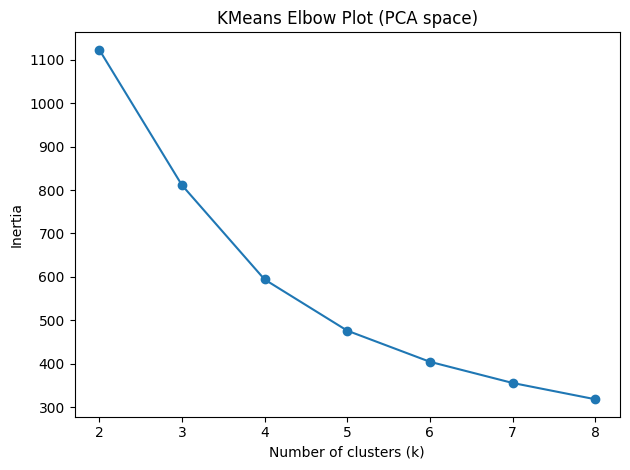

In [21]:
inertias = []
k_values = range(2, 9)  # k = 2..8

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_cluster)
    inertias.append(km.inertia_)

fig, ax = plt.subplots()
ax.plot(k_values, inertias, marker="o")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_title("KMeans Elbow Plot (PCA space)")

fig.tight_layout()
plt.show()


In [22]:
K = 5  # adjust after checking the elbow plot

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
pca_df["archetype"] = kmeans.fit_predict(X_cluster)

pca_df["archetype"].value_counts().sort_index()


archetype
0     60
1    133
2     43
3     68
4     20
Name: count, dtype: int64

In [23]:
cluster_profile_cols = [
    "minutes_90s",
    "xThreat_per90",
    "xThreat_pass_per90",
    "xThreat_carry_per90",
    "xThreat_total",
    "xg_total",
]

cluster_profiles = (
    pca_df.groupby("archetype")[cluster_profile_cols]
          .mean()
          .round(3)
)

cluster_profiles


,minutes_90s,xThreat_per90,xThreat_pass_per90,xThreat_carry_per90,xThreat_total,xg_total
archetype,,,,,,
0,29.263,0.141,0.128,0.013,3.885,3.016
1,23.884,0.085,0.077,0.008,1.859,2.057
2,22.755,0.143,0.082,0.061,3.110,4.968
3,14.884,0.038,0.031,0.007,0.554,2.001
4,31.538,0.238,0.215,0.023,7.308,3.394
